In [2]:
#Import Library
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as tr
%matplotlib inline
import seaborn as sns
from matplotlib.widgets import RadioButtons

In [6]:
#impport data
df=pd.read_csv('insurance.csv',encoding='latin1')

In [7]:
df.shape

(37542, 16)

In [ ]:
df.head()

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37542 entries, 0 to 37541
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               37542 non-null  str    
 1   BirthDate        37542 non-null  str    
 2   CarColor         37542 non-null  str    
 3   CarMake          37542 non-null  str    
 4   CarModel         37542 non-null  str    
 5   CarUse           37542 non-null  str    
 6   CarYear          37542 non-null  int64  
 7   CoverageZone     37542 non-null  str    
 8   Education        37542 non-null  str    
 9   Gender           37542 non-null  str    
 10  MaritalStatus    37542 non-null  str    
 11  Parent           37542 non-null  str    
 12  ClaimAmount      37542 non-null  float64
 13  ClaimFreq        37542 non-null  int64  
 14  HouseholdIncome  37542 non-null  float64
 15  KidsDriving      37542 non-null  int64  
dtypes: float64(2), int64(3), str(11)
memory usage: 7.4 MB


In [ ]:
#check for null values
pd.isnull(df).sum()

In [11]:
# change data type
df['BirthDate']=pd.to_datetime(df['BirthDate'],format='%d-%m-%Y')

In [8]:
df['BirthDate'].dtypes

dtype('<M8[us]')

In [21]:
df.columns

Index(['ID', 'BirthDate', 'CarColor', 'CarMake', 'CarModel', 'CarUse',
       'CarYear', 'CoverageZone', 'Education', 'Gender', 'MaritalStatus',
       'Parent', 'ClaimAmount', 'ClaimFreq', 'HouseholdIncome', 'KidsDriving'],
      dtype='str')

In [ ]:
# describe() method returns description of the data in the DataFrame (i.e. count, mean, std, etc)
df.describe()

In [ ]:
# use describe() for specific columns
df[['CarMake', 'CarModel', 'CarUse','Education']].describe()

# Exploratory Data Analysis

## Car Use

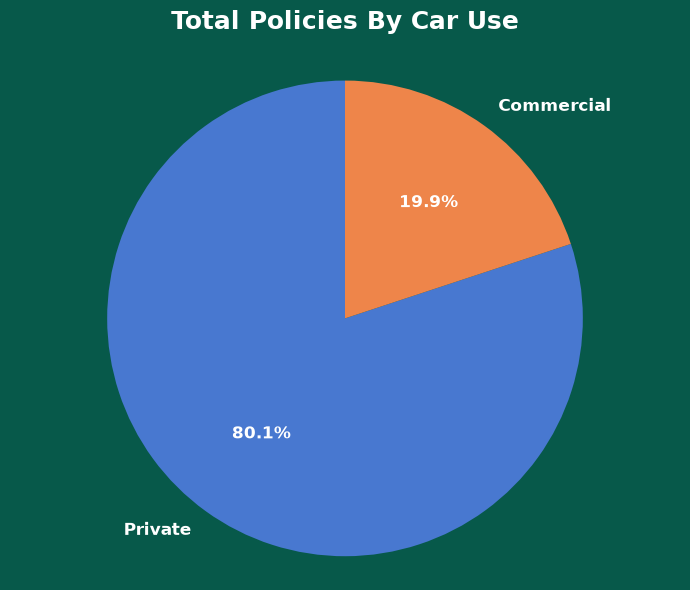

In [9]:
# plotting a Pie chart for Car Use
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
car_use=df['CarUse'].value_counts()                               #data for car use
labels=car_use.index.to_list()                                                #exact counts
sizes=car_use.values
patette_colors=sns.color_palette('muted',len(sizes))
ax.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=patette_colors,
    textprops=dict(color='white',weight='bold',fontsize=12)
)
ax.axis('equal')
plt.title('Total Policies By Car Use',fontsize=18,weight='bold',color='white',pad=20)
plt.tight_layout()
plt.show()

## Car Make

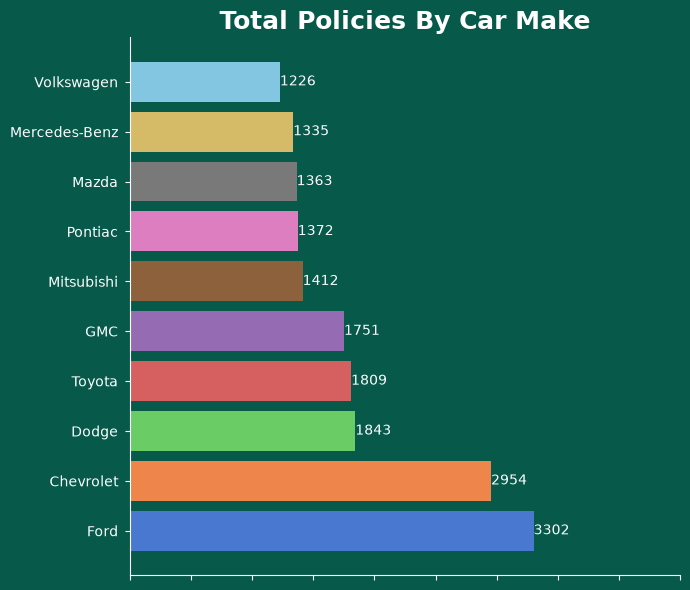

In [15]:
# plotting a horizontal chart for Car Make

plt.style.use('dark_background')
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
car_make=df['CarMake'].value_counts().head(10)                             #data for car use
patette_colors=sns.color_palette('muted',len(car_make))                # use seaborn color
# create horizontal chart
bars=ax.barh(
        car_make.index,
        car_make.values,
        color=patette_colors,
)
ax.bar_label(bars)
# set styling lables ,title and axes
ax.set_title('Total Policies By Car Make',fontsize=18,color='white',fontweight='bold')
ax.tick_params(colors='white',pad=5)
ax.set_xlim(0,4500)
ax.set_xticklabels([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')

plt.tight_layout()
plt.show()

## Coverage Zone.

In [ ]:
# plotting a Pie chart for Total Policies By Coverage Zone.
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')

coverage=df['CoverageZone'].value_counts()                               #data for car use
labels=coverage.index                                             #exact counts
sizes=coverage.values
patette_colors=sns.color_palette('muted',len(sizes))
ax.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=patette_colors,
    pctdistance=0.75,
    labeldistance=1.15,
    textprops=dict(color='white',weight='bold',fontsize=12),
    wedgeprops=dict(width=0.35,edgecolor="#27b6af",linewidth=2)
)
ax.axis('equal')
plt.title('Total Policies By Coverage Zone',fontsize=18,color="#FFFFFF",weight='bold')
plt.tight_layout()
plt.show()

## Age Group 

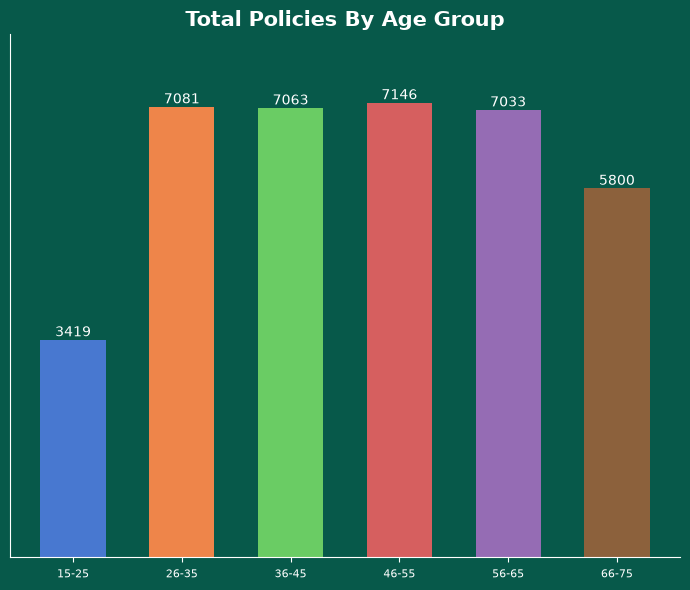

In [25]:
# plotting a Pie chart for Total Policies By Age Group.
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
bins=[14,25,35,45,55,65,75]
labels=['15-25','26-35','36-45','46-55','56-65','66-75']
df['Age']=2026-df['BirthDate'].dt.year
df['agegroup']=pd.cut(df['Age'],bins=bins,labels=labels)
agegroup=df['agegroup'].value_counts().sort_index()
patette_colors=sns.color_palette('muted',len(agegroup))     # use seaborn color
# create horizontal chart
ax.bar(
        agegroup.index,
        agegroup.values,
        color=patette_colors,
        width=0.6
)
ax.set_title('Total Policies By Age Group',fontsize=15,color="#FFFFFF",weight='bold')
# set styling lables ,title and axes
ax.bar_label(bars)
ax.tick_params(colors='white',labelsize=10,pad=5)
ax.set_xticks(range(len(agegroup.index)))
ax.set_xticklabels(agegroup.index,color='white',fontsize=8)  
#remove top and right spines for clean look
ax.set_ylim(0,agegroup.max()*1.15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('white')
ax.spines['bottom'].set_color('white')
ax.yaxis.set_visible(False)      #hide Y-axis numbers 
plt.subplots_adjust(bottom=0.2)                                
plt.tight_layout()
plt.show()

## Car Year

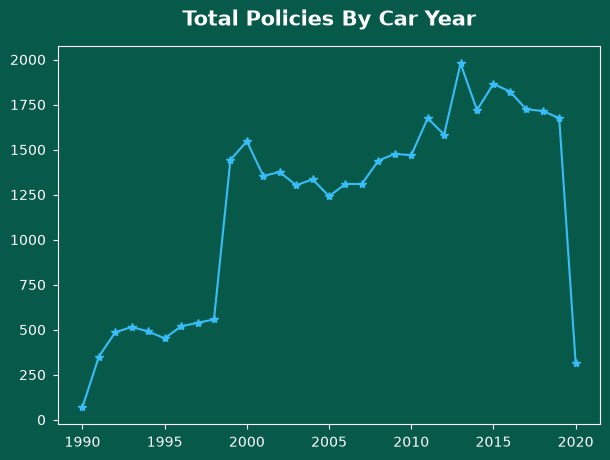

In [32]:
# plotting a line chart for Total Policies By Age Group.
caryear_cnt=df['CarYear'].value_counts().sort_index()
caryear_cnt=caryear_cnt[(caryear_cnt.index>=1990)&(caryear_cnt<=2020)]
# set up dark back group
plt.style.use('dark_background')
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor("#07594A")
# use seaborn for color
patette_colors=sns.color_palette('muted',len(caryear_cnt))    
# create vartical line chart
ax.plot(
        caryear_cnt.index.astype(str),
        caryear_cnt.values,
        color='#38bdf8',
        linewidth=1.5,
        marker='*',
        markersize=6,
        markerfacecolor='#38bdf8'
)              
ax.set_title('Total Policies By Car Year',fontsize=15,color="#FFFFFF",weight='bold',pad=15)
# set styling lables ,title and axes
ax.tick_params(colors='white',labelsize=10,pad=5)
ax.set_xticks(range(0,len(caryear_cnt),5))
ax.set_xticklabels(caryear_cnt.index[::5],color='white',fontsize=10) 
plt.subplots_adjust(bottom=0.25)   
plt.show()

## KIDs Driving

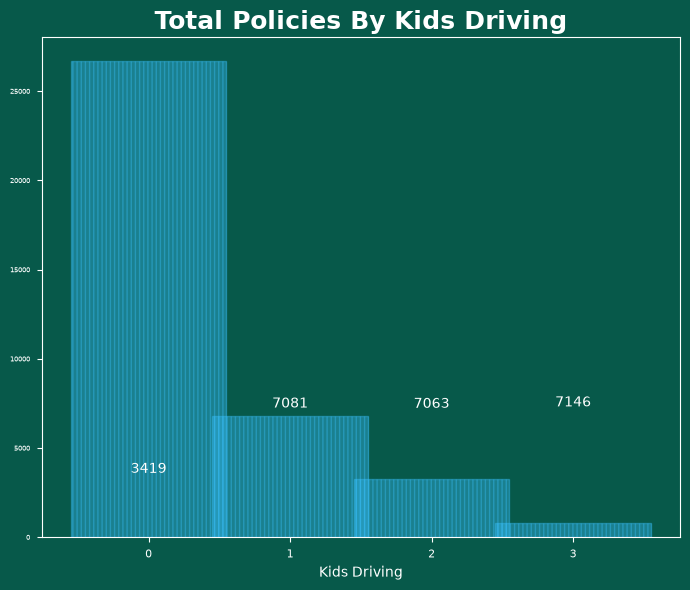

In [35]:
# plotting a Area chart for Total Policies By kids Driving.
kids_cnt=df['KidsDriving'].value_counts().sort_index()
# set up dark background
plt.style.use('dark_background')
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
# use seaborn color
pattle_colors=sns.color_palette('colorblind',len(kids_cnt))
ax.bar(
    kids_cnt.index.astype(str),
    kids_cnt.values,
    color='#38bdf8',
    width=1.1,
    alpha=0.4,
    hatch='||||',
    edgecolor='#38bdf8'
)
# set styling lables ,title and axes
ax.set_title('Total Policies By Kids Driving',fontsize=18,color="#FFFFFF",weight='bold')
ax.bar_label(bars)
ax.set_xlabel('Kids Driving')
ax.tick_params(colors='white',labelsize=10,pad=5)
ax.set_xticks(range(len(kids_cnt)))
ax.set_xticklabels(kids_cnt.index,color='white',fontsize=8)  
ax.yaxis.set_visible(True)      
ax.tick_params(axis='y',colors='white',labelsize=5)
plt.subplots_adjust(bottom=0.2) 
plt.tight_layout()
plt.show()

## Education 

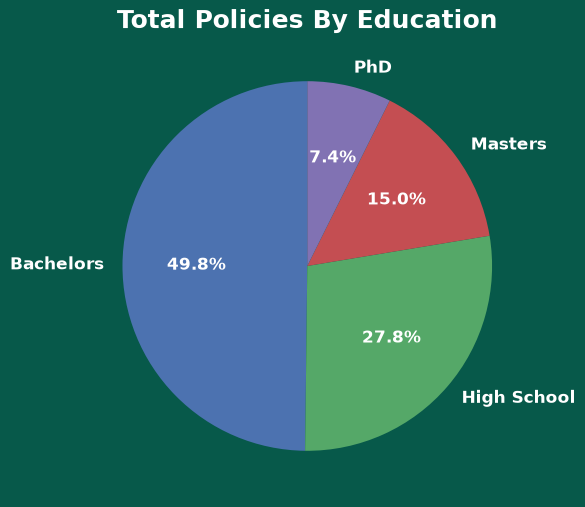

In [86]:
# plotting a pie chart for Total Policies By Education.
edu_cnt=df['Education'].value_counts().sort_index()
# set up dark background
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
colors=sns.color_palette('deep6',len(edu_cnt))
wedges,texts,autotexts=ax.pie(
    edu_cnt.values,
    labels=edu_cnt.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    textprops=dict(color='white',weight='bold',fontsize=12)
)
ax.set_title('Total Policies By Education',fontsize=18,color='white',weight='bold',pad=5)
plt.show()


## Education And Marital Status

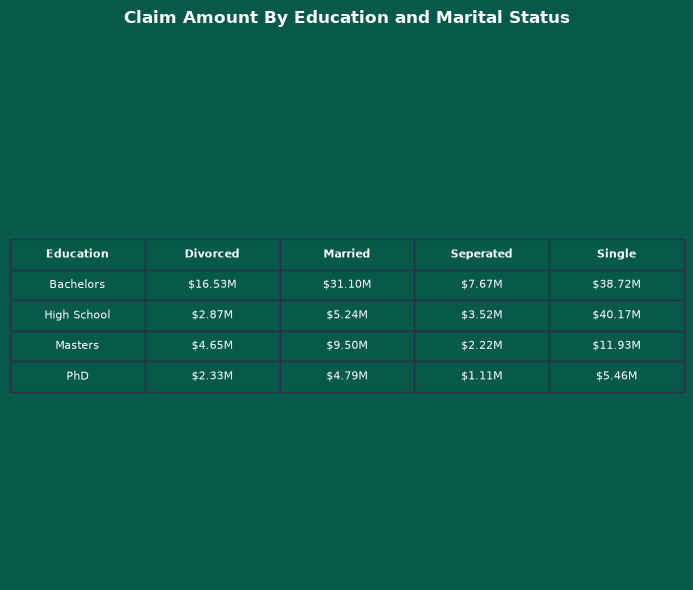

In [91]:
# plotting a Matrix for Total Policies By Education And Marital Status.
pivot_df=df.pivot_table(
    index='Education',
    columns='MaritalStatus',
    values='ClaimAmount',
    aggfunc='sum'
)
# format as currency string with M
pivot_reset=pivot_df.reset_index().drop(columns=['index'],errors='ignore')
pivot_format=pivot_reset.map(lambda x:f'${x/1e6:.2f}M' if isinstance(x,(int,float)) else str(x))
# set up dark background
fig,ax=plt.subplots(figsize=(7,6))
fig.patch.set_facecolor('#07594A')
ax.set_facecolor('#07594A')
ax.axis('off')
# render table
table=ax.table(
    cellText=pivot_format.values,
    # rowLabels=pivot_format.index,
    colLabels=pivot_format.columns,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.2,1.6)
# apply dark theme styling to cells
for (row,col), cell in table.get_celld().items():
    cell.set_facecolor('#07594A')
    cell.set_text_props(color='white')
    cell.set_edgecolor('#2d2d44')
    if row==0 or col==-1:
        cell.set_text_props(weight='bold',color='white')

ax.set_title('Claim Amount By Education and Marital Status',fontsize=12,color='white',weight='bold',pad=20)
plt.show()


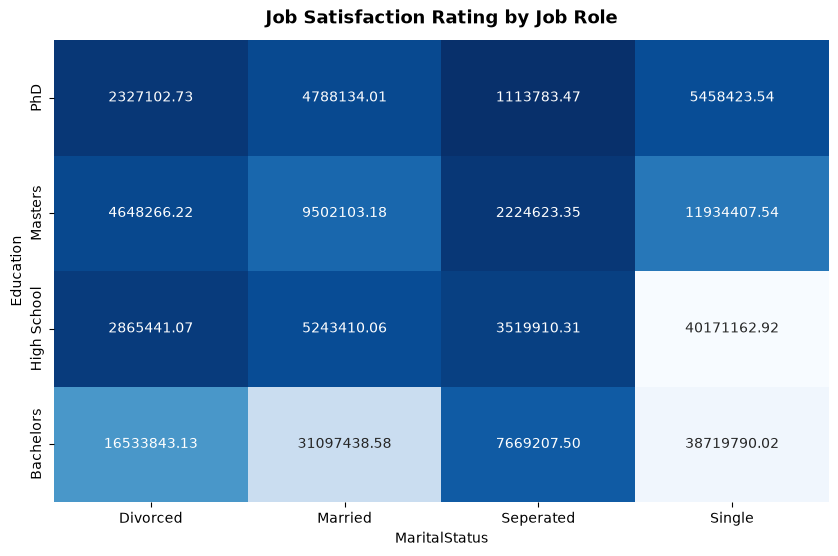

In [10]:
fig,ax=plt.subplots(figsize=(10,6))
df['ClaimAmount']=pd.to_numeric(df['ClaimAmount'].astype(str).str.replace(r'[^0-9.-]','',regex=True),errors='coerce').fillna(0)
pivot_df=df.pivot_table(
    index='Education',
    columns='MaritalStatus',
    values='ClaimAmount',
    aggfunc='sum',
    fill_value=0
)
pivot_df['Total'] = pivot_df.sum(axis=1)
pivot_df = pivot_df.sort_values(by='Total')
plt_data=pivot_df.drop(columns=['Total'])
sns.heatmap(
    plt_data,
    annot=True,          # Displays the numbers inside each cell
    fmt='.2f',             # Formats numbers as integers (no decimals)
    cmap='Blues_r',        # Palette gradient: Blues, YlGnBu, viridis, etc.
    # linewidths=0.5,      # Grid line separation between cells
    cbar=False,           # Color bar legend on the right
    ax=ax
)
ax.set_title('Job Satisfaction Rating by Job Role', fontsize=13, fontweight='bold', pad=12)
plt.show()